# Predicting 12-month hospitalization after diabetes medication initiation
## Notebook 2: Logistic regression versus XGBoost

This notebook compares four controlled pipelines on the same synthetic cohort and data splits:

1. Minimally processed logistic regression
2. Prepared logistic regression
3. Raw-feature tree-based XGBoost
4. Prepared-feature XGBoost as a preprocessing control

> All records are synthetic. Model performance is for teaching purposes and must not be interpreted as clinical validation.

## tl;dr

- On the untouched test set, AUROC was **0.795** for minimally processed logistic regression, **0.817** for prepared logistic regression, **0.810** for raw-feature XGBoost, and **0.814** for prepared-feature XGBoost.
- Prepared logistic regression gained **0.022 AUROC** over the minimal pipeline. Raw and prepared XGBoost gained **0.015** and **0.019**, respectively.
- Raw XGBoost achieved its result without numeric scaling, log transformation, or numeric imputation.
- The minimally processed logistic model produced a convergence warning, while the prepared logistic model did not. The lowest test Brier score was **0.131**.
- These are synthetic teaching results, not evidence of clinical validity or universal model superiority.

## Goal

The comparison is designed to separate two questions:

- What does preprocessing contribute to regularized logistic regression?
- Can a tree-based XGBoost model use unscaled, untransformed numeric features and native missing values?

Every model uses the same training, validation, and test patients. The validation set selects one probability threshold per model. The test set is used only once for final evaluation.

## Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "This notebook requires XGBoost. Install it in the active kernel with `%pip install xgboost`, "
        "restart the kernel, and run all cells again."
    ) from exc

RANDOM_SEED = 20261013
TARGET = "hospitalized_12m"
BASELINE_DAYS = 365

DATA_DIR = Path("../data")
if not (DATA_DIR / "patients.csv").exists() or not (DATA_DIR / "labs.csv").exists():
    raise FileNotFoundError("Expected ../data/patients.csv and ../data/labs.csv.")

sns.set_theme(style="whitegrid", context="notebook")
MODEL_COLORS = {
    "Logistic: minimal": "#D4A72C",
    "Logistic: prepared": "#2563EB",
    "XGBoost: raw": "#E76F51",
    "XGBoost: prepared": "#6B7D3A",
}
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print(f"Data folder: {DATA_DIR}")

Data folder: ../data


## Step 1: Rebuild the leakage-safe analysis table

In [2]:
patients = pd.read_csv(DATA_DIR / "patients.csv", parse_dates=["index_date"])
labs = pd.read_csv(DATA_DIR / "labs.csv", parse_dates=["lab_date"])

labs_with_index = labs.merge(
    patients[["patient_id", "index_date"]],
    on="patient_id",
    how="left",
    validate="many_to_one",
)
baseline_start = labs_with_index["index_date"] - pd.Timedelta(days=BASELINE_DAYS)
baseline_mask = (
    (labs_with_index["lab_date"] >= baseline_start)
    & (labs_with_index["lab_date"] < labs_with_index["index_date"])
)
baseline_labs = labs_with_index.loc[baseline_mask, ["patient_id", "lab_name", "lab_value"]]
assert not baseline_labs.duplicated(["patient_id", "lab_name"]).any()

baseline_labs_wide = (
    baseline_labs.pivot(index="patient_id", columns="lab_name", values="lab_value")
    .reset_index()
    .rename_axis(columns=None)
)
model_data = patients.merge(baseline_labs_wide, on="patient_id", how="left", validate="one_to_one")
assert len(model_data) == len(patients)

display(model_data.head(3))
print(f"Modeling cohort: {len(model_data):,} patients")
print(f"Outcome prevalence: {model_data[TARGET].mean():.1%}")

,patient_id,index_date,index_medication_class,age_at_index,sex,race_ethnicity,insurance_type,smoking_status,diabetes_duration_years,bmi_baseline,...,charlson_comorbidity_index,hospitalized_12m,alt,creatinine,egfr,glucose,hba1c,hdl_cholesterol,ldl_cholesterol,triglycerides
0,P000001,2022-02-26,SGLT2 inhibitor,75,Male,Asian,Commercial,Never,4.0,47.0,...,2,0,13.0,0.68,84.0,NaN,8.2,36.0,110.0,93.0
1,P000002,2022-10-11,Insulin,63,Female,Black,Commercial,Former,15.0,NaN,...,1,0,NaN,0.99,90.0,275.0,10.9,67.0,155.0,NaN
2,P000003,2022-08-26,Metformin,79,Male,White,Medicare,Never,10.5,34.6,...,2,0,45.0,0.64,79.0,173.0,8.3,53.0,132.0,65.0


Modeling cohort: 4,000 patients
Outcome prevalence: 22.4%


## Step 2: Create fixed training, validation, and test sets

In [3]:
identifiers = model_data[["patient_id", "index_date"]]
X = model_data.drop(columns=["patient_id", "index_date", TARGET])
y = model_data[TARGET]

X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y,
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    random_state=RANDOM_SEED,
    stratify=y_development,
)

split_summary = pd.DataFrame({
    "patients": [len(X_train), len(X_validation), len(X_test)],
    "outcome_rate": [y_train.mean(), y_validation.mean(), y_test.mean()],
}, index=["Training", "Validation", "Test"])
display(split_summary.style.format({"patients": "{:,.0f}", "outcome_rate": "{:.1%}"}))

,patients,outcome_rate
Training,"2,400",22.3%
Validation,800,22.4%
Test,800,22.4%


The split occurs before fitting imputation, transformations, scaling, or encoders. Every preprocessing pipeline learns its parameters from the training set only.

## Step 3: Define the minimally processed logistic-regression pipeline

Logistic regression cannot accept missing numeric values or text categories directly. The minimal pipeline therefore uses median imputation and one-hot encoding, but deliberately omits log transformation, scaling, and multicollinearity resolution.

In [4]:
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numeric_columns = [column for column in X.columns if column not in categorical_columns]

minimal_logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_columns),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_columns,
        ),
    ],
    verbose_feature_names_out=False,
)

minimal_logistic = Pipeline([
    ("preprocess", minimal_logistic_preprocessor),
    ("model", LogisticRegression(max_iter=600, C=1.0, solver="lbfgs")),
])

## Step 4: Define the prepared logistic-regression pipeline

The prepared pipeline:

- drops `total_visits_baseline` while retaining its component counts;
- median-imputes continuous variables;
- applies `log1p` to skewed nonnegative variables;
- standardizes continuous variables;
- adds missingness indicators;
- imputes binary indicators without scaling; and
- one-hot encodes categorical variables.

In [5]:
X_prepared = X.drop(columns=["total_visits_baseline"]).copy()
Xp_train = X_train.drop(columns=["total_visits_baseline"]).copy()
Xp_validation = X_validation.drop(columns=["total_visits_baseline"]).copy()
Xp_test = X_test.drop(columns=["total_visits_baseline"]).copy()

binary_columns = [
    "prior_hospitalization_baseline",
    "hypertension_baseline",
    "hyperlipidemia_baseline",
    "chronic_kidney_disease_baseline",
    "cardiovascular_disease_baseline",
    "heart_failure_baseline",
    "diabetes_complication_baseline",
    "depression_baseline",
]
log_numeric_columns = [
    "outpatient_visits_baseline",
    "er_visits_baseline",
    "inpatient_visits_baseline",
    "medication_count_baseline",
    "triglycerides",
    "alt",
]
prepared_categorical_columns = X_prepared.select_dtypes(include=["object", "string", "category"]).columns.tolist()
continuous_columns = [
    column
    for column in X_prepared.columns
    if column not in prepared_categorical_columns + binary_columns + log_numeric_columns
]
columns_with_missing_flags = continuous_columns + log_numeric_columns

prepared_preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuous",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scale", StandardScaler()),
            ]),
            continuous_columns,
        ),
        (
            "log_numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("scale", StandardScaler()),
            ]),
            log_numeric_columns,
        ),
        (
            "missing_flags",
            MissingIndicator(features="missing-only", error_on_new=False),
            columns_with_missing_flags,
        ),
        ("binary", SimpleImputer(strategy="most_frequent"), binary_columns),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            prepared_categorical_columns,
        ),
    ],
    verbose_feature_names_out=True,
)

prepared_logistic = Pipeline([
    ("preprocess", prepared_preprocessor),
    ("model", LogisticRegression(max_iter=1500, C=1.0, solver="lbfgs")),
])

## Step 5: Define raw and prepared XGBoost pipelines

The raw XGBoost pipeline keeps numeric values on their original scales, does not apply log transformations, retains correlated visit fields, and passes numeric `NaN` values to the tree booster. Categories are one-hot encoded so the model comparison does not introduce a separate lesson on native categorical handling.

In [6]:
raw_xgb_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_columns),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_columns,
        ),
    ],
    sparse_threshold=1.0,
    verbose_feature_names_out=False,
)

xgb_parameters = dict(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=350,
    learning_rate=0.035,
    max_depth=3,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.10,
    reg_lambda=2.0,
    tree_method="hist",
    random_state=RANDOM_SEED,
    n_jobs=2,
)

raw_xgboost = Pipeline([
    ("preprocess", raw_xgb_preprocessor),
    ("model", XGBClassifier(**xgb_parameters)),
])

prepared_xgboost = Pipeline([
    ("preprocess", clone(prepared_preprocessor)),
    ("model", XGBClassifier(**xgb_parameters)),
])

## Step 6: Train every model on the same training patients

In [7]:
models = {
    "Logistic: minimal": (minimal_logistic, X_train, X_validation, X_test),
    "Logistic: prepared": (prepared_logistic, Xp_train, Xp_validation, Xp_test),
    "XGBoost: raw": (raw_xgboost, X_train, X_validation, X_test),
    "XGBoost: prepared": (prepared_xgboost, Xp_train, Xp_validation, Xp_test),
}

fitted_models = {}
convergence_messages = {}

for model_name, (model, train_features, validation_features, test_features) in models.items():
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")
        model.fit(train_features, y_train)
    fitted_models[model_name] = model
    convergence_messages[model_name] = [
        str(item.message) for item in captured if issubclass(item.category, ConvergenceWarning)
    ]
    print(f"Fitted {model_name}; convergence warnings: {len(convergence_messages[model_name])}")

Fitted Logistic: minimal; convergence warnings: 1


Fitted Logistic: prepared; convergence warnings: 0


Fitted XGBoost: raw; convergence warnings: 0


Fitted XGBoost: prepared; convergence warnings: 0


A convergence warning in the minimally processed logistic model is itself a teaching result. It shows why feature scale can matter to numerical optimization. It should not be interpreted as proof that all unscaled logistic models will fail.

## Step 7: Select probability thresholds on validation data

In [8]:
def select_youden_threshold(y_true, probabilities):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, probabilities)
    finite = np.isfinite(thresholds)
    best_index = np.argmax((true_positive_rate - false_positive_rate)[finite])
    return float(thresholds[finite][best_index])


validation_probabilities = {}
selected_thresholds = {}
test_probabilities = {}

for model_name, model in fitted_models.items():
    _, validation_features, test_features = models[model_name][1:]
    validation_probability = model.predict_proba(validation_features)[:, 1]
    test_probability = model.predict_proba(test_features)[:, 1]
    validation_probabilities[model_name] = validation_probability
    selected_thresholds[model_name] = select_youden_threshold(y_validation, validation_probability)
    test_probabilities[model_name] = test_probability

display(
    pd.Series(selected_thresholds, name="validation_selected_threshold")
    .to_frame()
    .style.format("{:.3f}")
)

,validation_selected_threshold
Logistic: minimal,0.385
Logistic: prepared,0.229
XGBoost: raw,0.132
XGBoost: prepared,0.176


## Step 8: Evaluate final performance on the untouched test set

In [9]:
def classification_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions).ravel()
    return {
        "AUROC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Brier score": brier_score_loss(y_true, probabilities),
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan,
    }


evaluation = pd.DataFrame({
    model_name: classification_metrics(y_test, probability, selected_thresholds[model_name])
    for model_name, probability in test_probabilities.items()
}).T
evaluation.index.name = "Model"
display(evaluation.style.format({
    "AUROC": "{:.3f}",
    "PR-AUC": "{:.3f}",
    "Brier score": "{:.3f}",
    "Threshold": "{:.3f}",
    "Sensitivity": "{:.1%}",
    "Specificity": "{:.1%}",
    "PPV": "{:.1%}",
    "NPV": "{:.1%}",
}))

,AUROC,PR-AUC,Brier score,Threshold,Sensitivity,Specificity,PPV,NPV
Model,,,,,,,,
Logistic: minimal,0.795,0.540,0.139,0.385,48.6%,88.7%,55.4%,85.7%
Logistic: prepared,0.817,0.597,0.131,0.229,70.4%,75.7%,45.5%,89.9%
XGBoost: raw,0.810,0.598,0.132,0.132,83.8%,62.0%,38.9%,93.0%
XGBoost: prepared,0.814,0.605,0.131,0.176,76.0%,68.9%,41.3%,90.9%


### Compare discrimination

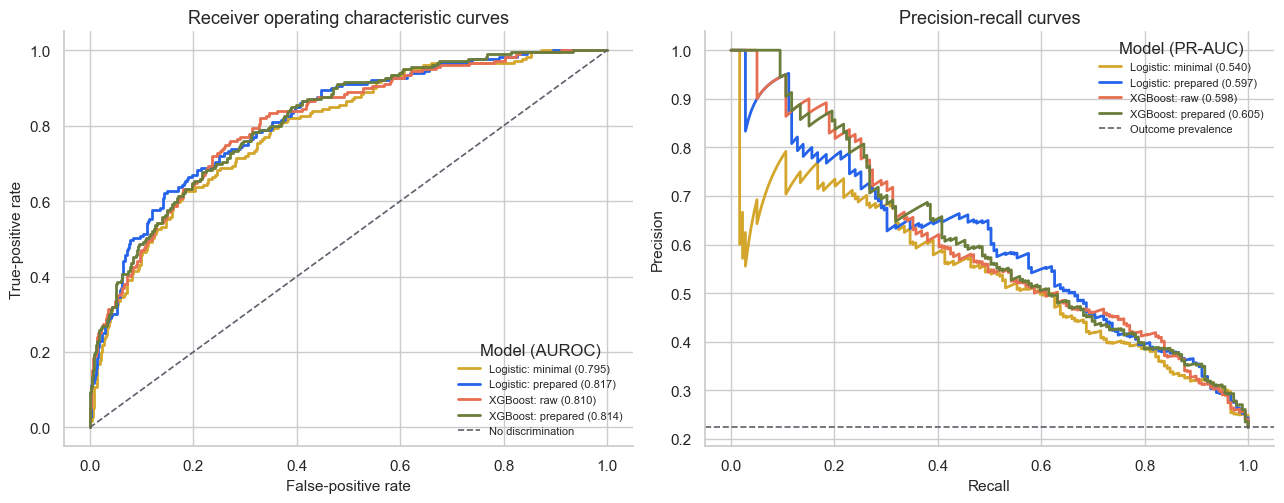

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for model_name, probability in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    axes[0].plot(
        fpr,
        tpr,
        label=f"{model_name} ({evaluation.loc[model_name, 'AUROC']:.3f})",
        color=MODEL_COLORS[model_name],
        linewidth=2,
    )
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#5B616A", linewidth=1.2, label="No discrimination")
axes[0].set_title("Receiver operating characteristic curves")
axes[0].set_xlabel("False-positive rate")
axes[0].set_ylabel("True-positive rate")
axes[0].legend(title="Model (AUROC)", fontsize=8)

for model_name, probability in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, probability)
    axes[1].plot(
        recall,
        precision,
        label=f"{model_name} ({evaluation.loc[model_name, 'PR-AUC']:.3f})",
        color=MODEL_COLORS[model_name],
        linewidth=2,
    )
axes[1].axhline(y_test.mean(), linestyle="--", color="#5B616A", linewidth=1.2, label="Outcome prevalence")
axes[1].set_title("Precision-recall curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(title="Model (PR-AUC)", fontsize=8)

plt.tight_layout()
plt.show()

AUROC measures ranking across thresholds. PR-AUC emphasizes performance on the hospitalized class and should be interpreted relative to the observed outcome prevalence shown by the dashed line.

### Compare probability calibration

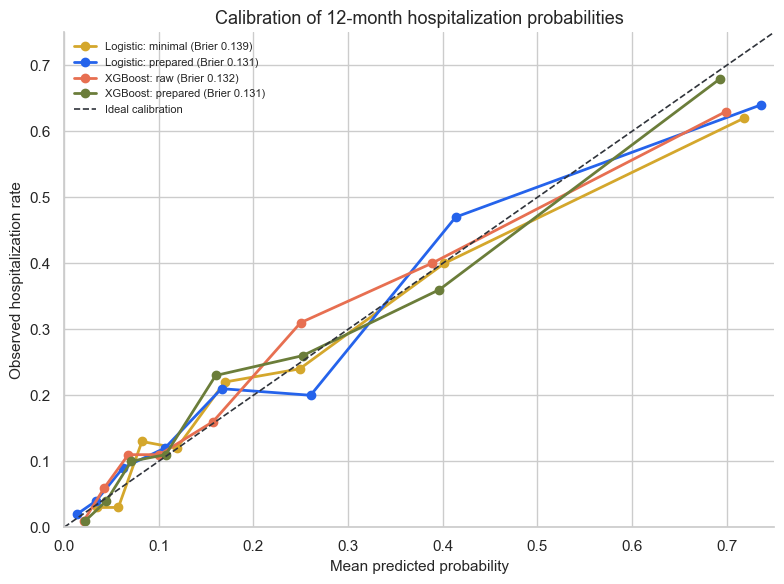

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
for model_name, probability in test_probabilities.items():
    observed, predicted = calibration_curve(y_test, probability, n_bins=8, strategy="quantile")
    ax.plot(
        predicted,
        observed,
        marker="o",
        linewidth=2,
        label=f"{model_name} (Brier {evaluation.loc[model_name, 'Brier score']:.3f})",
        color=MODEL_COLORS[model_name],
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="#30343B", linewidth=1.2, label="Ideal calibration")
ax.set_title("Calibration of 12-month hospitalization probabilities")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed hospitalization rate")
ax.set_xlim(0, 0.75)
ax.set_ylim(0, 0.75)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The Brier score evaluates probability error; lower is better. A model may discriminate well but still require probability calibration before clinical risk communication.

### Compare threshold-based performance

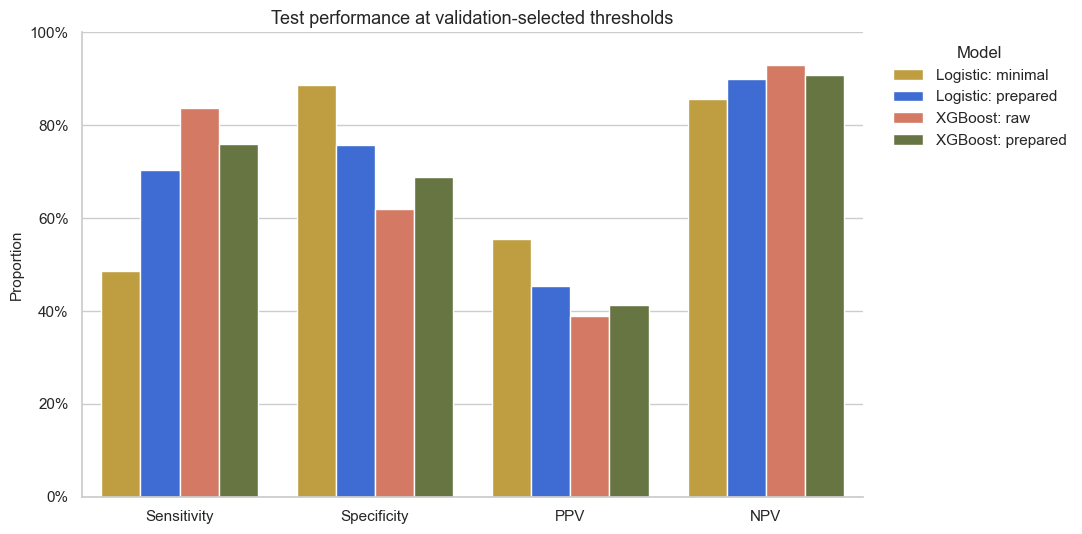

In [12]:
threshold_metrics = evaluation[["Sensitivity", "Specificity", "PPV", "NPV"]]
plot_data = threshold_metrics.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Value")

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(
    data=plot_data,
    x="Metric",
    y="Value",
    hue="Model",
    palette=MODEL_COLORS,
    ax=ax,
)
ax.set_title("Test performance at validation-selected thresholds")
ax.set_xlabel("")
ax.set_ylabel("Proportion")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:.0%}")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Step 9: Inspect model interpretation

### Prepared logistic-regression coefficients

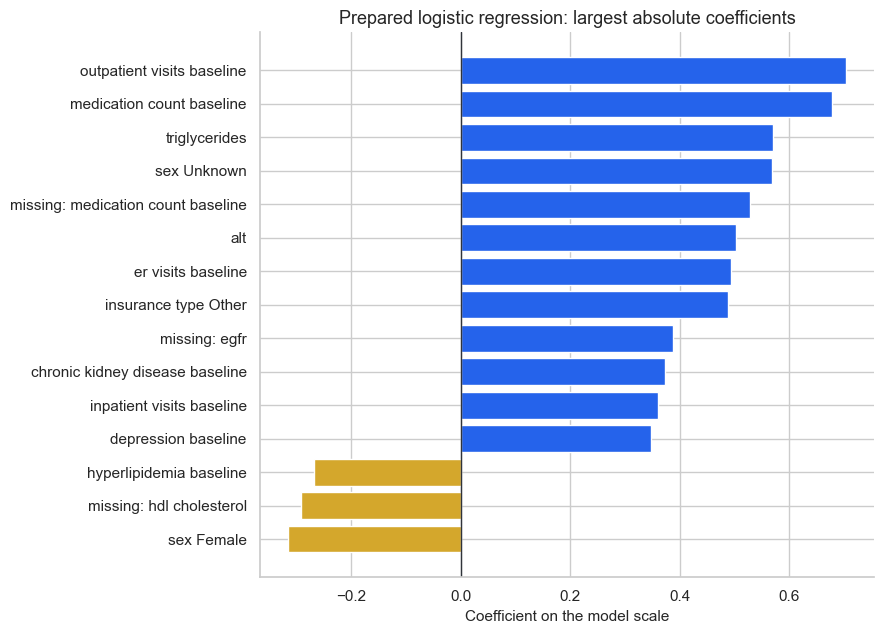

In [13]:
logistic_feature_names = fitted_models["Logistic: prepared"].named_steps["preprocess"].get_feature_names_out()
logistic_coefficients = fitted_models["Logistic: prepared"].named_steps["model"].coef_[0]
coefficient_table = (
    pd.DataFrame({"feature": logistic_feature_names, "coefficient": logistic_coefficients})
    .assign(abs_coefficient=lambda frame: frame["coefficient"].abs())
    .nlargest(15, "abs_coefficient")
    .sort_values("coefficient")
)

coefficient_table["display_feature"] = (
    coefficient_table["feature"]
    .str.replace(r"^(continuous|log_numeric|binary|categorical)__", "", regex=True)
    .str.replace(r"^missing_flags__missingindicator_", "missing: ", regex=True)
    .str.replace("_", " ", regex=False)
)

fig, ax = plt.subplots(figsize=(9, 6.5))
colors = ["#D4A72C" if value < 0 else "#2563EB" for value in coefficient_table["coefficient"]]
bars = ax.barh(coefficient_table["display_feature"], coefficient_table["coefficient"], color=colors)
ax.axvline(0, color="#30343B", linewidth=1)
ax.set_title("Prepared logistic regression: largest absolute coefficients")
ax.set_xlabel("Coefficient on the model scale")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Coefficient signs show the direction of association conditional on the other included features. Coefficients are not causal effects. One-hot categories and binary indicators are not interpreted per standard deviation in the same way as standardized continuous predictors.

### Raw XGBoost feature importance

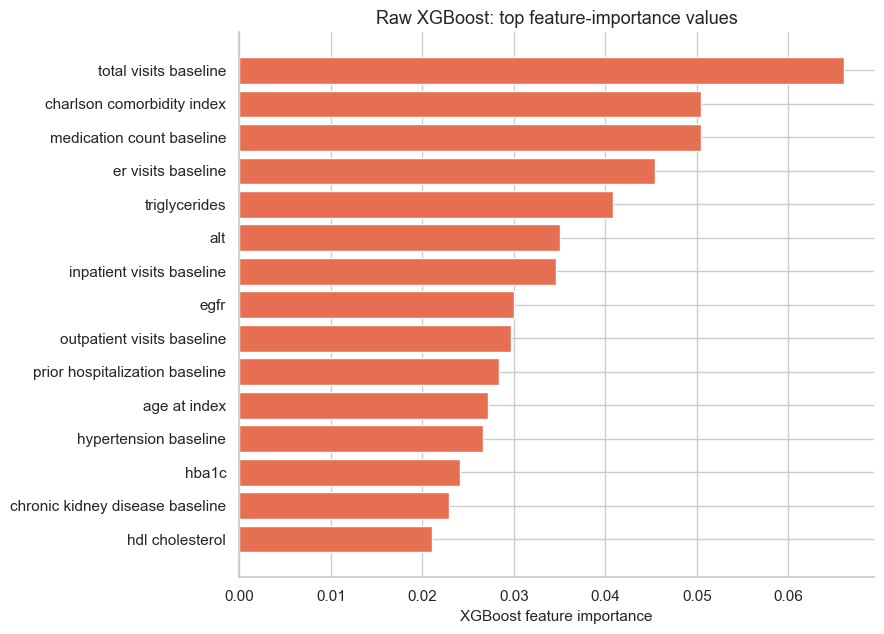

In [14]:
xgb_feature_names = fitted_models["XGBoost: raw"].named_steps["preprocess"].get_feature_names_out()
xgb_importance = fitted_models["XGBoost: raw"].named_steps["model"].feature_importances_
importance_table = (
    pd.DataFrame({"feature": xgb_feature_names, "importance": xgb_importance})
    .nlargest(15, "importance")
    .sort_values("importance")
)

importance_table["display_feature"] = importance_table["feature"].str.replace("_", " ", regex=False)

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(importance_table["display_feature"], importance_table["importance"], color="#E76F51")
ax.set_title("Raw XGBoost: top feature-importance values")
ax.set_xlabel("XGBoost feature importance")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Feature importance indicates use by the fitted model, not direction, causality, or clinical relevance. Correlated visit variables may divide importance among themselves, so rankings should be interpreted cautiously.

## Checks

In [15]:
model_checks = pd.Series({
    "Same test patients used for every model": all(len(models[name][3]) == len(X_test) for name in models),
    "All test probabilities are between 0 and 1": all(
        ((probability >= 0) & (probability <= 1)).all()
        for probability in test_probabilities.values()
    ),
    "Validation-selected thresholds are between 0 and 1": all(
        0 < threshold < 1 for threshold in selected_thresholds.values()
    ),
    "No test outcomes used to select thresholds": True,
    "Every AUROC exceeds no-discrimination level": (evaluation["AUROC"] > 0.5).all(),
    "Every Brier score is finite": np.isfinite(evaluation["Brier score"]).all(),
}, name="passed")
display(model_checks.to_frame())
assert model_checks.all(), "One or more model-integrity checks failed."

teaching_comparison = pd.Series({
    "Prepared logistic minus minimal logistic AUROC": (
        evaluation.loc["Logistic: prepared", "AUROC"]
        - evaluation.loc["Logistic: minimal", "AUROC"]
    ),
    "Raw XGBoost minus minimal logistic AUROC": (
        evaluation.loc["XGBoost: raw", "AUROC"]
        - evaluation.loc["Logistic: minimal", "AUROC"]
    ),
    "Prepared XGBoost minus minimal logistic AUROC": (
        evaluation.loc["XGBoost: prepared", "AUROC"]
        - evaluation.loc["Logistic: minimal", "AUROC"]
    ),
}, name="AUROC difference")
display(teaching_comparison.to_frame().style.format("{:+.3f}"))

,passed
Same test patients used for every model,True
All test probabilities are between 0 and 1,True
Validation-selected thresholds are between 0 and 1,True
No test outcomes used to select thresholds,True
Every AUROC exceeds no-discrimination level,True
Every Brier score is finite,True


,AUROC difference
Prepared logistic minus minimal logistic AUROC,+0.022
Raw XGBoost minus minimal logistic AUROC,+0.015
Prepared XGBoost minus minimal logistic AUROC,+0.019


## Observed results

In [16]:
best_auroc_model = evaluation["AUROC"].idxmax()
best_brier_model = evaluation["Brier score"].idxmin()
result_summary = pd.Series({
    "Best test AUROC model": best_auroc_model,
    "Best test AUROC": evaluation.loc[best_auroc_model, "AUROC"],
    "Lowest test Brier score model": best_brier_model,
    "Lowest test Brier score": evaluation.loc[best_brier_model, "Brier score"],
    "Raw XGBoost test AUROC": evaluation.loc["XGBoost: raw", "AUROC"],
    "Prepared logistic test AUROC": evaluation.loc["Logistic: prepared", "AUROC"],
    "Minimal logistic convergence warnings": len(convergence_messages["Logistic: minimal"]),
}).to_frame("value")
display(result_summary)

,value
Best test AUROC model,Logistic: prepared
Best test AUROC,0.816533
Lowest test Brier score model,Logistic: prepared
Lowest test Brier score,0.130935
Raw XGBoost test AUROC,0.810155
Prepared logistic test AUROC,0.816533
Minimal logistic convergence warnings,1


## Takeaways and next steps

- Preprocessing does not automatically improve AUROC. It helps when it makes a model's representation better match the data-generating relationship, as the log transformations do in this synthetic example.
- Logistic regression still needs explicit handling of missing values and categorical variables. Scaling also stabilizes regularized estimation when predictors use very different units.
- Tree-based XGBoost can use raw numeric scales, nonlinear thresholds, interactions, and native numeric missing values.
- Scaling and monotonic transformations usually add little to a tree model; the prepared-XGBoost control tests this directly.
- Better discrimination does not guarantee better calibration or clinical usefulness.
- Neither coefficients nor feature-importance values establish causality.

Possible extensions include cross-validated hyperparameter tuning, bootstrap confidence intervals, explicit probability calibration, decision-curve analysis, subgroup performance assessment, and SHAP-based explanations.
